# Método de Euler para ecuaciones diferenciales

**Historia, explicación, por qué hacerlo en Python y qué puede fallar**

Este notebook acompaña a la app **Euler·Lab** del repositorio (`python euler_app.py`), que muestra el método paso a paso: a la izquierda el registro de cada cálculo y a la derecha la gráfica. Aquí está la teoría detrás de lo que se ve en la app.

| | Sección |
|---|---|
| 1 | **Historia**: de la poligonal de Euler (1768) a las redes neuronales |
| 2 | **Explicación**: deducción, geometría, ejemplo a mano, error, estabilidad, aplicación |
| 3 | **¿En qué ayuda que esté en Python?** |
| 4 | **¿Qué puede fallar?** (y cómo darse cuenta) |
| 5 | **La app Euler·Lab**: qué muestra y cómo está construida |
| 6 | **Agregar otro método**: punto medio y Euler implícito |
| 7 | Conclusiones y referencias |

In [1]:
import sys, time
sys.path.insert(0, "..")          # para importar el paquete edo desde la carpeta notebooks/

import numpy as np
import matplotlib.pyplot as plt

from edo import (Configuracion, Simulacion, ProblemaValorInicial, MetodoNumerico, registrar,
                 resolver, orden_observado, ejemplos, metodos_disponibles, obtener_metodo)
from edo import graficas
from edo.app.tema import aplicar_tema, GRAFICA, ETAPAS, UI
from edo.app.efectos import resplandor

aplicar_tema()                     # el mismo tema oscuro de la app, también para estas gráficas
plt.rcParams["figure.figsize"] = (9, 4.6)
plt.rcParams["figure.dpi"] = 100
print("Métodos disponibles:", metodos_disponibles())

Métodos disponibles: ['euler', 'heun', 'rk4']


## 1. Historia

**Antes de Euler.** Con el cálculo de Newton y Leibniz (1680s) apareció un nuevo tipo de problema: conocer la *rapidez de cambio* de una cantidad y querer recuperar la cantidad misma. Las leyes de la mecánica, del crecimiento o del enfriamiento se escriben de forma natural como **ecuaciones diferenciales**. El problema es que casi ninguna se puede resolver con una fórmula cerrada: incluso algo tan inocente como $y' = x^2 + y^2$ no tiene solución en funciones elementales. Desde el inicio hubo que *aproximar*. Leibniz ya pensaba las curvas como polígonos formados por pedacitos de tangente infinitamente pequeños.

**Euler, 1768.** Leonhard Euler convirtió esa intuición en un procedimiento de cálculo en el primer volumen de *Institutionum calculi integralis* (1768–1770): partir del punto conocido, avanzar un trecho pequeño en la dirección que indica la ecuación, y repetir. El resultado es una **poligonal** que sigue a la solución. Euler lo presentó como una forma práctica de obtener valores numéricos cuando no se sabe integrar la ecuación, y señaló que la aproximación mejora conforme los pasos se hacen más pequeños.

**Cauchy, década de 1820.** Augustin-Louis Cauchy, en sus lecciones de análisis en la École Polytechnique, demostró que las poligonales de Euler **convergen** cuando el paso tiende a cero. Con eso probó algo más profundo: que la solución *existe*. El método de Euler pasó de ser una receta de cálculo a ser una herramienta de demostración (hoy se le conoce también como *poligonal de Euler–Cauchy*). Más tarde Lipschitz dio la condición que garantiza que esa solución es **única**.

**Runge, Heun y Kutta (1895–1901).** Carl Runge (1895) propuso mejorar a Euler evaluando la pendiente en más de un punto por paso; Karl Heun (1900) y Martin Kutta (1901) sistematizaron la idea. Así nacieron los métodos de **Runge–Kutta**, incluido el famoso RK4. Todos son descendientes directos de Euler: Euler es el Runge–Kutta de una sola etapa.

**Las computadoras (1940s–1960s).** Con las primeras computadoras electrónicas (ENIAC, 1946, se usó para calcular trayectorias balísticas) los métodos paso a paso se volvieron la forma estándar de resolver ecuaciones diferenciales. Aparecieron también sus límites: Curtiss y Hirschfelder (1952) llamaron **rígidas** (*stiff*) a las ecuaciones en las que los métodos explícitos como Euler necesitan pasos absurdamente pequeños, y Germund Dahlquist (1956, 1963) desarrolló la **teoría de estabilidad** que explica por qué.

**Hoy.** Nadie usa Euler para cálculos de precisión, pero sigue en todas partes: es el primer método que se enseña, es la base de los demás, se usa en simulaciones físicas en tiempo real (videojuegos) y reapareció en el aprendizaje automático: una red neuronal residual (ResNet) hace, capa por capa, $h_{k+1} = h_k + f(h_k)$, que es exactamente un paso de Euler; de esa observación salieron las *Neural ODEs* (2018).

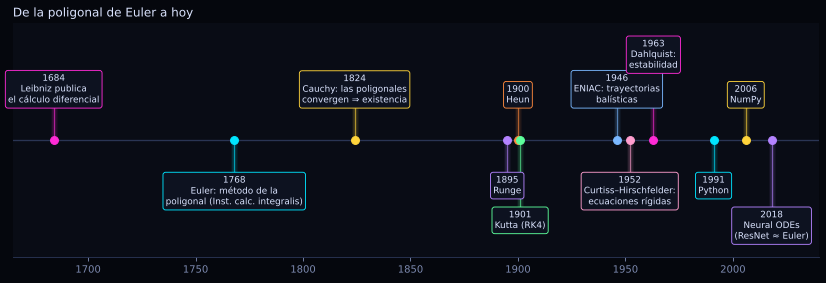

In [2]:
eventos = [
    (1684, "Leibniz publica\nel cálculo diferencial", 1),
    (1768, "Euler: método de la\npoligonal (Inst. calc. integralis)", -1),
    (1824, "Cauchy: las poligonales\nconvergen ⇒ existencia", 1),
    (1895, "Runge", -1), (1900, "Heun", 1), (1901, "Kutta (RK4)", -2),
    (1946, "ENIAC: trayectorias\nbalísticas", 1),
    (1952, "Curtiss–Hirschfelder:\necuaciones rígidas", -1),
    (1963, "Dahlquist:\nestabilidad", 2),
    (1991, "Python", -1), (2006, "NumPy", 1), (2018, "Neural ODEs\n(ResNet ≈ Euler)", -2),
]
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.axhline(0, color=GRAFICA["eje"], lw=1.2)
colores = [GRAFICA["metodo"], GRAFICA["referencia"], GRAFICA["tangente"], *ETAPAS[1:]]
for i, (anio, texto, nivel) in enumerate(eventos):
    c = colores[i % len(colores)]
    ax.plot([anio, anio], [0, nivel * 0.9], color=c, lw=1, alpha=0.6)
    ax.plot(anio, 0, "o", color=c, ms=7, zorder=5)
    ax.text(anio, nivel * 0.95, f"{anio}\n{texto}", ha="center", va="bottom" if nivel > 0 else "top",
            fontsize=8, color=UI["texto"], bbox=dict(boxstyle="round,pad=0.3", fc=UI["panel_alto"], ec=c, lw=0.8))
ax.set_ylim(-3.2, 3.2)
ax.set_xlim(1665, 2040)
ax.set_yticks([])
for lado in ("left", "top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_title("De la poligonal de Euler a hoy", loc="left")
resplandor(ax, capas=4, alcance=5, intensidad=0.06)
plt.show()

## 2. Explicación

### 2.1 El problema

Un **problema de valor inicial** (PVI) de primer orden es

$$
y'(x) = f(x, y), \qquad y(x_0) = y_0, \qquad x \in [x_0, X].
$$

La ecuación no da $y$, da su **pendiente** en cada punto del plano. Un método numérico no busca una fórmula para $y(x)$, sino números $y_n \approx y(x_n)$ en una malla

$$
x_n = x_0 + n\,h, \qquad n = 0, 1, \dots, N, \qquad h = \frac{X - x_0}{N}.
$$

A $h$ se le llama **tamaño de paso**.

### 2.2 Tres formas de llegar a la misma fórmula

**(a) Por la definición de derivada.** Para $h$ pequeño, $y'(x_n) \approx \dfrac{y(x_n + h) - y(x_n)}{h}$. Como $y'(x_n) = f(x_n, y_n)$, despejamos:

$$
\boxed{\,y_{n+1} = y_n + h\, f(x_n, y_n)\,}
$$

**(b) Por Taylor.** $y(x_n + h) = y(x_n) + h\,y'(x_n) + \tfrac{h^2}{2}\,y''(\xi_n)$. Euler se queda con los dos primeros términos y **desprecia** $\tfrac{h^2}{2}y''(\xi_n)$: ese es el *error local de truncamiento*, de tamaño $O(h^2)$.

**(c) Por integración.** $y(x_{n+1}) = y(x_n) + \int_{x_n}^{x_{n+1}} f(x, y(x))\,dx$. Euler aproxima la integral con un **rectángulo** de altura $f(x_n, y_n)$ (el valor del extremo izquierdo). Mejorar esa aproximación de la integral (trapecio, Simpson...) es justo lo que hacen Heun y RK4.

### 2.3 Geometría

La ecuación dibuja un **campo de pendientes**: en cada punto $(x, y)$ un segmentito con pendiente $f(x, y)$. Las soluciones son curvas tangentes a ese campo. Euler parte de $(x_0, y_0)$, lee la pendiente del campo ahí y avanza en **línea recta** una distancia $h$; en el punto nuevo vuelve a leer la pendiente, y así sucesivamente. En cada paso se forma un triángulo: cateto horizontal $h$, cateto vertical $h\,f(x_n, y_n)$. Eso es lo que la app dibuja en amarillo.

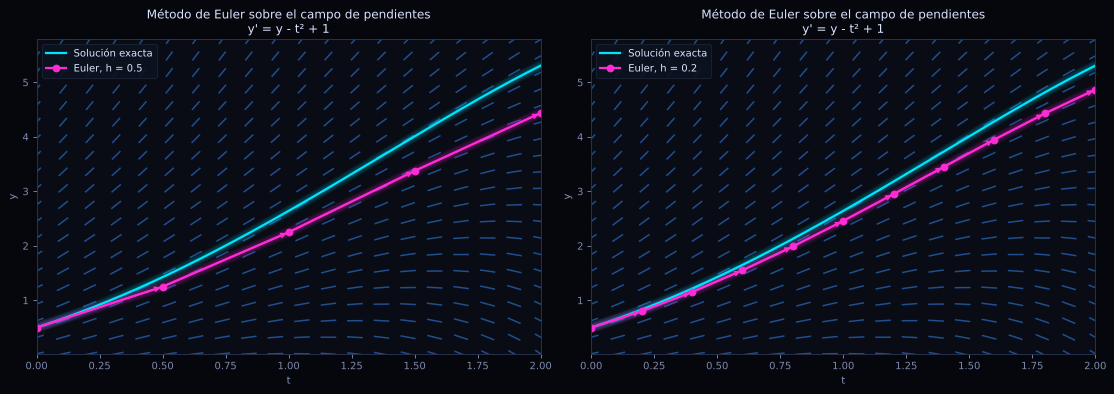

In [3]:
pvi = ejemplos.ejemplo_burden()        # y' = y - x² + 1, y(0) = 0.5, exacta (x+1)² - 0.5 eˣ
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
graficas.graficar_pasos_euler(pvi, h=0.5, ax=axs[0])
graficas.graficar_pasos_euler(pvi, h=0.2, ax=axs[1])
for ax in axs:
    resplandor(ax)
plt.tight_layout()
plt.show()

Con $h = 0.5$ la poligonal se separa rápido de la solución exacta; con $h = 0.2$ la sigue mejor. Euler **siempre se queda por debajo** en este ejemplo: la solución es cóncava hacia arriba al inicio, así que la tangente queda debajo de la curva, y como $\partial f/\partial y = 1 > 0$ ese error se va amplificando.

### 2.4 El algoritmo en Python

El método completo cabe en unas cuantas líneas:

In [4]:
def euler(f, x0, y0, h, n):
    xs, ys = [x0], [y0]
    for i in range(n):
        y0 = y0 + h * f(x0, y0)      # avanzar sobre la recta tangente
        x0 = xs[0] + (i + 1) * h     # (no x0 += h: ver la sección 4.8)
        xs.append(x0)
        ys.append(y0)
    return xs, ys

xs, ys = euler(lambda x, y: x + y, 0.0, 1.0, 0.1, 5)
for x, y in zip(xs, ys):
    print(f"x = {x:.1f}   y ≈ {y:.6f}   exacta = {2*np.exp(x) - x - 1:.6f}")

x = 0.0   y ≈ 1.000000   exacta = 1.000000
x = 0.1   y ≈ 1.100000   exacta = 1.110342
x = 0.2   y ≈ 1.220000   exacta = 1.242806
x = 0.3   y ≈ 1.362000   exacta = 1.399718
x = 0.4   y ≈ 1.528200   exacta = 1.583649
x = 0.5   y ≈ 1.721020   exacta = 1.797443


### 2.5 Ejemplo paso a paso (igual que en el registro de la app)

$y' = x + y$, $y(0) = 1$, $h = 0.1$. Solución exacta: $y = 2e^x - x - 1$. La clase `Simulacion` es la misma que usa la app: guarda cada paso con sus etapas, y el método sabe escribir su fórmula con los números sustituidos.

In [5]:
sim = Simulacion(Configuracion("x + y", x0=0, y0=1, h=0.1, x_final=0.5, metodo="euler", exacta="2exp(x) - x - 1"))
for paso in sim.pasos:
    k1 = paso.etapas[0]
    print(f"paso {paso.indice}:  k₁ = f({k1.t:.1f}, {float(k1.y):.4f}) = {float(k1.pendiente):.4f}")
    print("        " + sim.metodo.formula_numerica(paso))
print()
print(sim.resumen())

paso 0:  k₁ = f(0.0, 1.0000) = 1.0000
        y₁ = y₀ + h·k₁ = 1.0000 + 0.1000·1.0000 = 1.1000
paso 1:  k₁ = f(0.1, 1.1000) = 1.2000
        y₂ = y₁ + h·k₁ = 1.1000 + 0.1000·1.2000 = 1.2200
paso 2:  k₁ = f(0.2, 1.2200) = 1.4200
        y₃ = y₂ + h·k₁ = 1.2200 + 0.1000·1.4200 = 1.3620
paso 3:  k₁ = f(0.3, 1.3620) = 1.6620
        y₄ = y₃ + h·k₁ = 1.3620 + 0.1000·1.6620 = 1.5282
paso 4:  k₁ = f(0.4, 1.5282) = 1.9282
        y₅ = y₄ + h·k₁ = 1.5282 + 0.1000·1.9282 = 1.7210

Euler con h = 0.1: 5 pasos, y(0.5) ≈ 1.72102, error final ≈ 7.642e-02


### 2.6 Error y orden de convergencia

- **Error local**: lo que se pierde en *un* paso, $\tfrac{h^2}{2}y''(\xi) = O(h^2)$.
- **Error global**: lo que se acumula hasta el final. Son $N \approx (X - x_0)/h$ pasos, cada uno aporta $O(h^2)$, y además los errores se propagan; el resultado es $|y(X) - y_N| \le C\,h$. Euler es de **orden 1**: *si $h$ se divide entre 2, el error se divide entre 2*.

Si el error se comporta como $E(h) \approx C\,h^p$, el orden se puede medir: $p \approx \log(E(h_1)/E(h_2)) / \log(h_1/h_2)$.

        h     error máx  cociente  orden p
      0.2  4.396874e-01                   
      0.1  2.419719e-01     1.817   0.8616
     0.05  1.274657e-01     1.898   0.9247
    0.025  6.549505e-02     1.946   0.9607
   0.0125  3.320765e-02     1.972   0.9799
  0.00625  1.672143e-02     1.986   0.9898


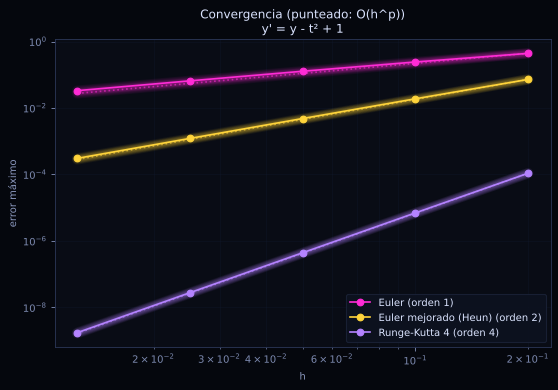

In [6]:
print(f"{'h':>9} {'error máx':>13} {'cociente':>9} {'orden p':>8}")
anterior = None
for h, err, p in orden_observado(pvi, "euler", [0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625]):
    cociente = "" if anterior is None else f"{anterior / err:.3f}"
    orden = "" if np.isnan(p) else f"{p:.4f}"
    print(f"{h:>9g} {err:>13.6e} {cociente:>9} {orden:>8}")
    anterior = err

ax = graficas.graficar_convergencia(pvi, ["euler", "heun", "rk4"], [0.2, 0.1, 0.05, 0.025, 0.0125])
resplandor(ax)
plt.show()

En escala log-log, un método de orden $p$ es una recta de pendiente $p$. Para el mismo error, RK4 necesita muchísimos menos pasos (aunque cada paso cuesta 4 evaluaciones de $f$ en lugar de 1).

### 2.7 Estabilidad: la ecuación de prueba $y' = \lambda y$

Con $\lambda < 0$ la solución exacta $y_0 e^{\lambda x}$ **decae** a cero. Euler da

$$
y_{n+1} = y_n + h\lambda\,y_n = (1 + h\lambda)\,y_n \quad\Longrightarrow\quad y_n = (1 + h\lambda)^n\,y_0 .
$$

Para que $y_n$ también decaiga hace falta $|1 + h\lambda| \le 1$, es decir

$$
h \le \frac{2}{|\lambda|}.
$$

Si $h$ es mayor, **el método explota aunque la solución verdadera sea tranquila**. A $R(z) = 1 + z$ (con $z = h\lambda$) se le llama *función de estabilidad*; cada método tiene la suya, y la app la usa para avisar cuando el paso es inestable.

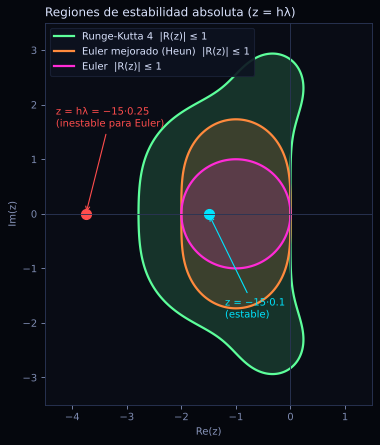

In [7]:
X, Y = np.meshgrid(np.linspace(-4.5, 1.5, 500), np.linspace(-3.5, 3.5, 500))
Z = X + 1j * Y
fig, ax = plt.subplots(figsize=(8, 6.2))
for nombre, c in (("rk4", ETAPAS[3]), ("heun", ETAPAS[2]), ("euler", GRAFICA["metodo"])):
    R = obtener_metodo(nombre).funcion_estabilidad(Z)
    ax.contourf(X, Y, np.abs(R), levels=[0, 1], colors=[c], alpha=0.16)
    ax.contour(X, Y, np.abs(R), levels=[1], colors=[c], linewidths=2)
    ax.plot([], [], color=c, lw=2, label=f"{obtener_metodo(nombre)}  |R(z)| ≤ 1")
ax.plot(-15 * 0.25, 0, "o", color=GRAFICA["error"], ms=9)
ax.annotate("z = hλ = −15·0.25\n(inestable para Euler)", (-3.75, 0), (-4.3, 1.6), color=GRAFICA["error"],
            arrowprops=dict(arrowstyle="->", color=GRAFICA["error"]))
ax.plot(-15 * 0.1, 0, "o", color=GRAFICA["referencia"], ms=9)
ax.annotate("z = −15·0.1\n(estable)", (-1.5, 0), (-1.2, -1.9), color=GRAFICA["referencia"],
            arrowprops=dict(arrowstyle="->", color=GRAFICA["referencia"]))
ax.axhline(0, color=GRAFICA["eje"], lw=0.8); ax.axvline(0, color=GRAFICA["eje"], lw=0.8)
ax.set_aspect("equal"); ax.set_xlabel("Re(z)"); ax.set_ylabel("Im(z)")
ax.set_title("Regiones de estabilidad absoluta (z = hλ)", loc="left")
ax.legend(loc="upper left")
plt.show()

La región de Euler es el círculo de radio 1 centrado en $-1$: sobre el eje real negativo, $-2 \le h\lambda \le 0$. Los métodos de mayor orden tienen regiones un poco más grandes, pero **todos los métodos explícitos tienen una región acotada**: para ecuaciones rígidas (λ muy negativo) obligan a usar $h$ muy pequeño. Por eso existen los métodos implícitos (sección 6).

### 2.8 Una aplicación: ¿cuándo se enfría el café?

Ley de enfriamiento de Newton: $T' = -k\,(T - T_a)$ con $T(0) = 90\,^\circ$C, $T_a = 20\,^\circ$C, $k = 0.1\ \text{min}^{-1}$. Solución exacta: $T = T_a + (T_0 - T_a)e^{-kt}$. ¿Cuándo llega a $40\,^\circ$C?

Tiempo exacto para llegar a 40 °C: 12.528 min

Euler h = 5    → t ≈  9.286 min   (error 3.242 min)
Euler h = 2    → t ≈ 11.281 min   (error 1.247 min)
Euler h = 0.5  → t ≈ 12.215 min   (error 0.313 min)
Euler h = 0.1  → t ≈ 12.465 min   (error 0.063 min)


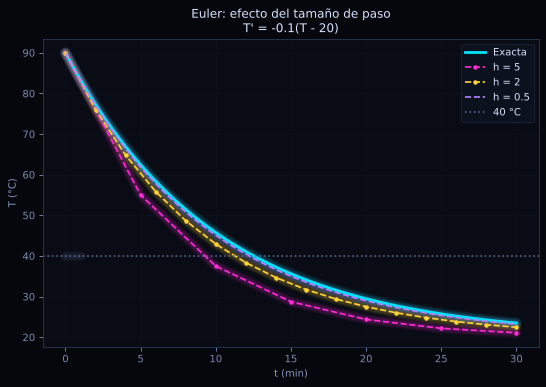

In [8]:
cafe = ejemplos.enfriamiento_newton(k=0.1, temperatura_ambiente=20, T0=90, t_final=30)
ax = graficas.comparar_pasos(cafe, [5, 2, 0.5])
ax.axhline(40, color=UI["texto_tenue"], ls=":", label="40 °C")
ax.set_ylabel("T (°C)"); ax.set_xlabel("t (min)"); ax.legend()
resplandor(ax)
plt.show()

t_exacto = -np.log((40 - 20) / (90 - 20)) / 0.1
print(f"Tiempo exacto para llegar a 40 °C: {t_exacto:.3f} min\n")
for h in (5, 2, 0.5, 0.1):
    s = resolver(cafe, "euler", h=h)
    i = np.argmax(s.y <= 40)
    t40 = s.t[i-1] + (40 - s.y[i-1]) * (s.t[i] - s.t[i-1]) / (s.y[i] - s.y[i-1])
    print(f"Euler h = {h:<4g} → t ≈ {t40:6.3f} min   (error {abs(t40 - t_exacto):.3f} min)")

Euler predice que el café se enfría **antes** de lo real (la curva es cóncava hacia arriba y la tangente queda por debajo), y el error en el tiempo baja más o menos en proporción a $h$: orden 1 otra vez.

## 3. ¿En qué ayuda que esté en Python?

### 3.1 El código se parece a la matemática

La fórmula $y_{n+1} = y_n + h\,f(x_n, y_n)$ y el código de `edo/metodos/euler.py` se leen casi igual:

```python
def paso(self, f, t, y, h):
    k1 = self.evaluar(f, t, y, "k1")   # pendiente en el punto de partida
    return y + h * k1                  # avanzar h sobre la recta tangente
```

Eso permite concentrarse en el método y no en el lenguaje. `self.evaluar` hace lo mismo que `f(t, y)`, pero además deja anotada la evaluación para que la app pueda mostrarla.

### 3.2 NumPy: el mismo código sirve para un número, un vector o miles de casos

Con arreglos de NumPy, `y + h * f(t, y)` funciona igual si `y` es un número, un vector (un **sistema** de ecuaciones) o un arreglo con **muchas condiciones iniciales a la vez**. Euler es secuencial en $x$ (cada paso depende del anterior), pero se puede vectorizar *a través* de las condiciones iniciales:

2000 problemas × 160 pasos:  ciclos de Python 0.26 s   NumPy 5.2 ms   → 49 veces más rápido


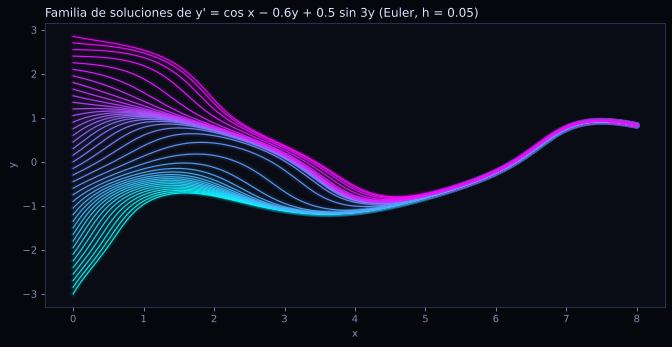

In [9]:
f = lambda x, y: np.cos(x) - 0.6 * y + 0.5 * np.sin(3 * y)
y0s = np.linspace(-3, 3, 2000)
h, n = 0.05, 160

t = time.perf_counter()                       # 1) un ciclo de Python por cada condición inicial
for y0 in y0s:
    x, y = 0.0, y0
    for i in range(n):
        y = y + h * f(x, y); x = (i + 1) * h
t_bucle = time.perf_counter() - t

t = time.perf_counter()                       # 2) todas las condiciones iniciales a la vez
Y = np.empty((n + 1, len(y0s))); Y[0] = y0s
for i in range(n):
    Y[i + 1] = Y[i] + h * f(i * h, Y[i])
t_numpy = time.perf_counter() - t
print(f"{len(y0s)} problemas × {n} pasos:  ciclos de Python {t_bucle:.2f} s   NumPy {t_numpy*1000:.1f} ms"
      f"   → {t_bucle / t_numpy:.0f} veces más rápido")

xs = np.arange(n + 1) * h
fig, ax = plt.subplots(figsize=(10, 4.6))
cmap = plt.get_cmap("cool")
for j in range(0, len(y0s), 50):
    ax.plot(xs, Y[:, j], color=cmap(j / len(y0s)), lw=1.1, alpha=0.9)
resplandor(ax, capas=3, alcance=5, intensidad=0.04)
ax.set_title("Familia de soluciones de y' = cos x − 0.6y + 0.5 sin 3y (Euler, h = 0.05)", loc="left")
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

### 3.3 Comprobar contra una referencia profesional

SciPy trae `solve_ivp`, con métodos adaptativos (RK45, Radau para problemas rígidos, LSODA...). Comparar contra él es una forma rápida de saber si nuestra implementación está bien. (La app no depende de SciPy: si no hay solución exacta usa RK4 con un paso 40–100 veces más fino como referencia.)

In [10]:
try:
    from scipy.integrate import solve_ivp
    ref = solve_ivp(lambda x, y: x + y, (0, 2), [1.0], method="RK45", rtol=1e-11, atol=1e-12, dense_output=True)
    sim = Simulacion(Configuracion("x + y", 0, 1, 0.1, 2, "euler"))
    print(f"y(2) exacta      = {2*np.exp(2) - 3:.10f}")
    print(f"y(2) solve_ivp   = {ref.sol(2.0)[0]:.10f}   ({ref.nfev} evaluaciones de f, paso adaptativo)")
    print(f"y(2) referencia  = {sim.referencia_en(2.0):.10f}   ({sim.etiqueta_referencia})")
    print(f"y(2) Euler h=0.1 = {sim.y_nodos[-1]:.10f}   ({sim.evaluaciones} evaluaciones de f)")
except ImportError:
    print("SciPy no está instalado (pip install scipy); no es necesario para el proyecto.")

y(2) exacta      = 11.7781121979
y(2) solve_ivp   = 11.7781121979   (560 evaluaciones de f, paso adaptativo)
y(2) referencia  = 11.7781121979   (referencia RK4 (h/40))
y(2) Euler h=0.1 = 10.4549998987   (20 evaluaciones de f)


### 3.4 Escribir la ecuación como texto, sin peligro

En la app la ecuación se escribe como texto (`x + y^2`). Lo más fácil sería `eval(texto)`, pero `eval` ejecuta **cualquier** código de Python, y además en Python `^` no es potencia sino *XOR* (`2^3 == 1`). El módulo `edo.expresion` usa el analizador de Python (`ast`) para aceptar solo números, variables, operaciones y funciones matemáticas de una lista blanca, y traduce la notación de clase:

In [11]:
from edo import compilar_edo, ErrorExpresion

print("en Python puro, 2^3 =", 2 ^ 3, "(XOR)")
for texto in ["y' = x + y^2", "dy/dx = 2xy", "3(x + 1)sen(x)", "e^(-x)·y"]:
    f = compilar_edo(texto)
    print(f"{texto:18} → {f.python:28} f(1, 2) = {f(1.0, 2.0):.4f}")
for malo in ["__import__('os').system('rm -rf /')", "x + sin y", "x + z"]:
    try:
        compilar_edo(malo)
    except ErrorExpresion as e:
        print(f"{malo!r:42} → rechazada: {e}")

en Python puro, 2^3 = 1 (XOR)
y' = x + y^2       → x + y ** 2                   f(1, 2) = 5.0000
dy/dx = 2xy        → 2 * x * y                    f(1, 2) = 4.0000
3(x + 1)sen(x)     → 3 * ( x + 1 ) * sen ( x )    f(1, 2) = 5.0488
e^(-x)·y           → e ** ( - x ) * y             f(1, 2) = 0.7358
"__import__('os').system('rm -rf /')"      → rechazada: Carácter no válido «'».
'x + sin y'                                → rechazada: La función 'sin' necesita paréntesis: sin(...)
'x + z'                                    → rechazada: Nombre desconocido 'z'. Variables válidas: t, x, y.


### 3.5 Resumen: ventajas y costos

| Ventaja | Qué significa aquí |
|---|---|
| Legible | La implementación de cada método es la fórmula del libro. |
| NumPy | Sistemas y familias de soluciones con el mismo código; campo de pendientes en una sola evaluación. |
| matplotlib | Gráficas, animación y la app completa sin instalar nada más. |
| Jupyter | Explicación, código y resultados juntos (este notebook). |
| Ecosistema | SciPy para comparar, SymPy para soluciones exactas, pytest para pruebas automáticas. |
| Clases y registro | Agregar un método nuevo es escribir una clase pequeña (sección 6). |

| Costo | Cómo se maneja |
|---|---|
| Los ciclos de Python son lentos | Vectorizar con NumPy cuando se puede; para trabajo serio, `solve_ivp` (compilado y adaptativo). |
| Errores de tipo y de redondeo silenciosos | Pruebas automáticas (`pytest`) y comparación contra soluciones conocidas. |
| `eval` es peligroso | Analizar la expresión con `ast` (sección 3.4). |

## 4. ¿Qué puede fallar?

El método de Euler **siempre da números**. El problema es que a veces esos números no tienen nada que ver con la solución, y el método no avisa. La app intenta detectar varios de estos casos (los muestra en el registro con ⚠ o ✖); aquí está cada uno con su explicación.

### 4.1 Paso demasiado grande: error grande y forma equivocada

El error global es proporcional a $h$. Con $h$ grande la poligonal puede incluso cambiar el *comportamiento cualitativo* de la solución (oscilar cuando no debería, cruzar un equilibrio, etc.).

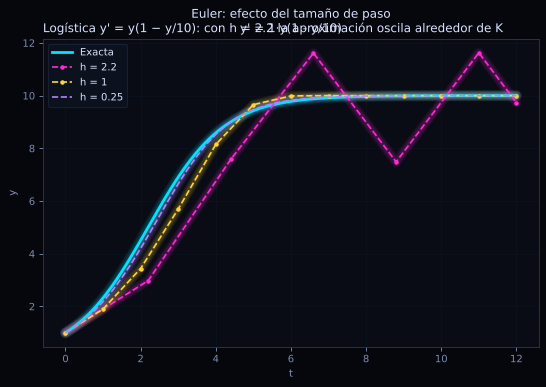

In [12]:
log = ejemplos.logistica(r=1.0, K=10.0, y0=1.0, t_final=12)
ax = graficas.comparar_pasos(log, [2.2, 1.0, 0.25])
ax.set_title("Logística y' = y(1 − y/10): con h = 2.2 la aproximación oscila alrededor de K", loc="left")
resplandor(ax)
plt.show()

### 4.2 Inestabilidad numérica (ecuaciones rígidas)

$y' = -15y$, $y(0)=1$: la solución exacta $e^{-15x}$ cae a cero casi de inmediato. Con $h = 0.25$, $h\lambda = -3.75$ está fuera del círculo de estabilidad: $|1 + h\lambda| = 2.75$, y cada paso multiplica el error por $-2.75$. La app lo detecta: estima $\lambda \approx \partial f/\partial y$ en cada paso y evalúa $|R(h\lambda)|$.

h = 0.25   y(2) ≈  3271   Inestable: ∂f/∂y ≈ -15 y |R(h·∂f/∂y)| = 2.75 > 1. El método amplifica el error; reduce h p…
h = 0.125  y(2) ≈  0.1181   sin avisos
h = 0.05   y(2) ≈  8.272e-25   sin avisos


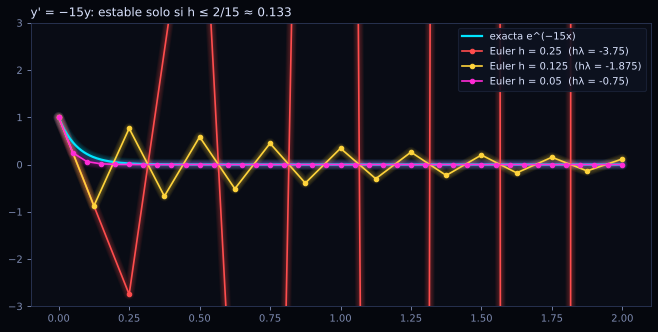

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.6))
xe = np.linspace(0, 2, 400)
ax.plot(xe, np.exp(-15 * xe), color=GRAFICA["referencia"], lw=2, label="exacta e^(−15x)")
for h, c in ((0.25, GRAFICA["error"]), (0.125, GRAFICA["tangente"]), (0.05, GRAFICA["metodo"])):
    s = Simulacion(Configuracion("-15y", 0, 1, h, 2, "euler"))
    ax.plot(s.x_nodos, s.y_nodos, "o-", color=c, ms=4, lw=1.5, label=f"Euler h = {h}  (hλ = {-15*h:g})")
    avisos = [a.mensaje for a in s.avisos if a.nivel == "aviso"]
    print(f"h = {h:<6} y(2) ≈ {s.y_nodos[-1]: .4g}   " + (avisos[0][:90] + "…" if avisos else "sin avisos"))
ax.set_ylim(-3, 3); ax.legend(); ax.set_title("y' = −15y: estable solo si h ≤ 2/15 ≈ 0.133", loc="left")
resplandor(ax)
plt.show()

Con $h = 0.125$ ($h\lambda = -1.875$) es estable pero **oscila**: $1 + h\lambda < 0$ cambia el signo en cada paso. Solo con $h\lambda \in [-1, 0]$ la aproximación decae sin oscilar.

### 4.3 Explosión en tiempo finito (asíntotas verticales)

$y' = y^2$, $y(0) = 1$ tiene solución $y = 1/(1 - x)$, que **no existe** más allá de $x = 1$. Euler no lo sabe: sigue dando números finitos después de la asíntota.

[aviso] La referencia se dispara cerca de x ≈ 1 (probable asíntota vertical), pero Euler siguió hasta x = 1.6 sin notarlo: esos valores no tienen sentido.


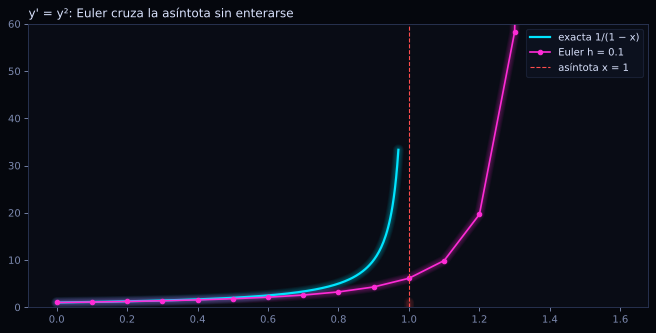

In [14]:
s = Simulacion(Configuracion("y^2", 0, 1, 0.1, 1.6, "euler", ""))
fig, ax = plt.subplots(figsize=(10, 4.6))
xe = np.linspace(0, 0.97, 300)
ax.plot(xe, 1 / (1 - xe), color=GRAFICA["referencia"], lw=2, label="exacta 1/(1 − x)")
ax.plot(s.x_nodos, s.y_nodos, "o-", color=GRAFICA["metodo"], ms=4, label="Euler h = 0.1")
ax.axvline(1, color=GRAFICA["error"], ls="--", lw=1, label="asíntota x = 1")
ax.set_ylim(0, 60); ax.legend(); ax.set_title("y' = y²: Euler cruza la asíntota sin enterarse", loc="left")
resplandor(ax)
plt.show()
for a in s.avisos:
    print(f"[{a.nivel}] {a.mensaje}")

### 4.4 Falta de unicidad

$y' = \sqrt{|y|}$, $y(0) = 0$ tiene **al menos dos** soluciones: $y = 0$ y $y = x^2/4$. La función $f$ no es Lipschitz en $y = 0$ (su derivada $\partial f/\partial y$ no está acotada ahí), así que el teorema de existencia y unicidad no aplica. Euler da $y_n = 0$ para siempre: encuentra una solución, pero no avisa que hay otras.

∂f/∂y no está acotada cerca de (x₀, y₀) = (0, 0): f no es Lipschitz ahí, así que la solución podría no ser única. El método seguirá solo una de ellas.


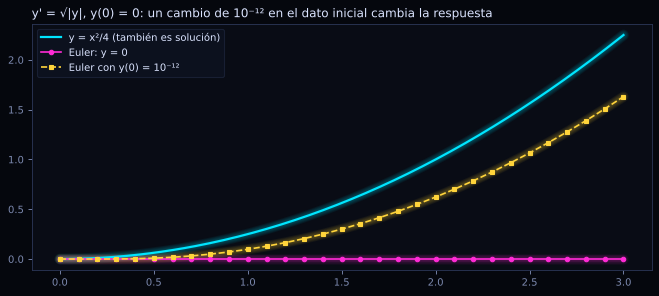

In [15]:
s = Simulacion(Configuracion("sqrt(abs(y))", 0, 0, 0.1, 3, "euler"))
fig, ax = plt.subplots(figsize=(10, 4))
xe = np.linspace(0, 3, 200)
ax.plot(xe, xe**2 / 4, color=GRAFICA["referencia"], lw=2, label="y = x²/4 (también es solución)")
ax.plot(s.x_nodos, s.y_nodos, "o-", color=GRAFICA["metodo"], ms=4, label="Euler: y = 0")
s2 = Simulacion(Configuracion("sqrt(abs(y))", 0, 1e-12, 0.1, 3, "euler"))
ax.plot(s2.x_nodos, s2.y_nodos, "s--", color=GRAFICA["tangente"], ms=3, label="Euler con y(0) = 10⁻¹²")
ax.legend(); ax.set_title("y' = √|y|, y(0) = 0: un cambio de 10⁻¹² en el dato inicial cambia la respuesta", loc="left")
resplandor(ax)
plt.show()
print(s.avisos[0].mensaje)

### 4.5 $f$ no definida o discontinua

Si en algún momento el método necesita $f$ donde no existe (división entre cero, logaritmo o raíz de un negativo), aparece `inf` o `nan` y todo lo que sigue es basura. La app se detiene en ese paso y lo dice. Con discontinuidades (por ejemplo $f$ con un `sign`), el método pierde su orden de convergencia cerca del salto.

In [16]:
s = Simulacion(Configuracion("1/(x - 1)", 0, 0, 0.25, 2, "euler"))
print(s.resumen())
for a in s.avisos:
    print(f"[{a.nivel}] {a.mensaje}")

Euler con h = 0.25: 4 pasos, y(1) ≈ -2.08333
[error] f(1, -2.083) = inf: f no está definida o es infinita ahí (¿división entre cero, log o raíz de negativo?).


### 4.6 No conserva lo que debería: el oscilador gana energía

Para $x'' + x = 0$ (como sistema $x' = v$, $v' = -x$) la energía $x^2 + v^2$ es constante. Euler cumple exactamente $x_{n+1}^2 + v_{n+1}^2 = (1 + h^2)(x_n^2 + v_n^2)$: **la energía crece en cada paso** y la órbita se abre en espiral, por pequeño que sea $h$. En simulaciones largas (órbitas, física de videojuegos) esto es grave; por eso existen los métodos *simplécticos*.

h = 0.1   energía inicial = 1.000  final = 6.509   (×6.51)
h = 0.02  energía inicial = 1.000  final = 1.458   (×1.46)


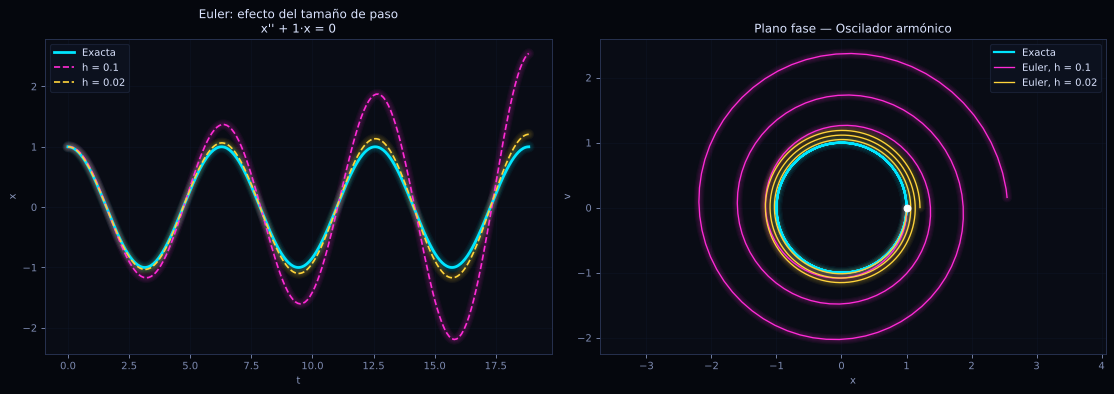

In [17]:
osc = ejemplos.oscilador_armonico(t_final=6 * np.pi)
sols = [resolver(osc, "euler", h=h) for h in (0.1, 0.02)]
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
graficas.comparar_pasos(osc, [0.1, 0.02], ax=axs[0])
graficas.graficar_plano_fase(sols, ax=axs[1])
for ax in axs:
    resplandor(ax, capas=4)
plt.tight_layout()
plt.show()
for s in sols:
    E = s.y[:, 0]**2 + s.y[:, 1]**2
    print(f"h = {s.h:<5g} energía inicial = {E[0]:.3f}  final = {E[-1]:.3f}   (×{E[-1]/E[0]:.2f})")

### 4.7 Redondeo: reducir $h$ no siempre ayuda

Cada operación en punto flotante tiene un error relativo del orden de $\varepsilon$: unos $10^{-16}$ en doble precisión (`float64`, la normal en Python), $10^{-7}$ en precisión simple y $10^{-3}$ en media precisión. Con $h$ más pequeño el error de truncamiento baja, pero hay **más pasos** y el redondeo se acumula. El error total tiene forma de "V": hay un $h$ óptimo por debajo del cual reducir el paso *empeora* el resultado. Con `float64` el fondo de la V queda tan abajo que casi nunca se alcanza; con menos precisión se ve claramente:

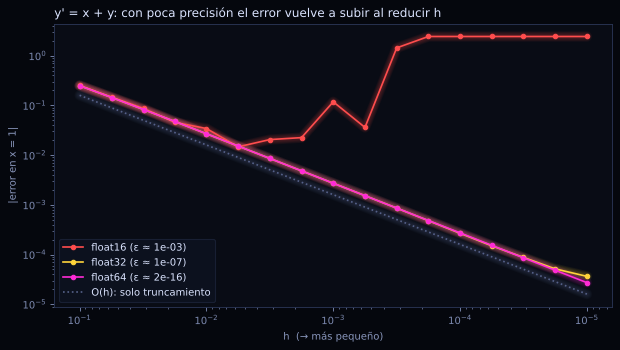

In [18]:
def euler_tipo(dtipo, n):
    h = dtipo(1 / n)                  # n pasos hasta x = 1 (h redondeado al tipo)
    y, x = dtipo(1), dtipo(0)
    for i in range(n):
        y = y + h * (x + y)
        x = dtipo((i + 1) / n)          # x_n = n·h, redondeado al tipo
    return float(y)

exacta = 2 * np.e - 2
ns = np.unique(np.round(np.logspace(1, 5, 17)).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.6))
for dtipo, c in ((np.float16, GRAFICA["error"]), (np.float32, GRAFICA["tangente"]), (np.float64, GRAFICA["metodo"])):
    errores = [abs(euler_tipo(dtipo, n) - exacta) for n in ns]
    ax.loglog(1 / ns, errores, "o-", color=c, ms=4, label=f"{dtipo.__name__} (ε ≈ {np.finfo(dtipo).eps:.0e})")
ax.loglog(1 / ns, 1.6 / ns, ":", color=UI["texto_tenue"], label="O(h): solo truncamiento")
ax.invert_xaxis(); ax.set_xlabel("h  (→ más pequeño)"); ax.set_ylabel("|error en x = 1|")
ax.set_title("y' = x + y: con poca precisión el error vuelve a subir al reducir h", loc="left"); ax.legend()
resplandor(ax)
plt.show()

Con `float16` pasan dos cosas: el redondeo acumulado hace que el error deje de bajar alrededor de $h \approx 10^{-2}$, y para $h$ aún menor aparece una **meseta**: cuando $h\,f(x_n, y_n)$ es más pequeño que la mitad de la distancia entre dos números representables cerca de $y_n$, la suma $y_n + h\,f$ se redondea a $y_n$ y el método se queda congelado. Con `float32` el efecto apenas empieza a notarse en $h = 10^{-5}$.

### 4.8 Errores típicos al programarlo en Python

Estos no son del método sino de la implementación, y son muy comunes:

In [19]:
# 1) ^ no es potencia
print("x^2 con x = 3 →", 3 ^ 2, "   (XOR; la potencia es 3**2 =", 3**2, ")")

# 2) Acumular x += h arrastra error de redondeo: el ciclo puede terminar un paso antes o después
x = 0.0
for _ in range(10):
    x += 0.1
print("0.1 sumado 10 veces =", repr(x), "  ¿== 1.0?", x == 1.0)
print("mejor: x0 + i*h →", 0.0 + 10 * 0.1)
# (y nunca usar `while x != x_final`: puede no terminar nunca)

# 3) Modificar arreglos en su lugar cambia también el original (alias)
y0 = np.array([1.0, 0.0])
y = y0             # ¡no es una copia!
y += 0.1 * np.array([0.0, -1.0])
print("y0 después de 'y += ...':", y0, "  ← se modificó la condición inicial")

# 4) math.sin no acepta arreglos; np.sin sí
import math
try:
    math.sin(np.array([0.0, 1.0]))
except TypeError as e:
    print("math.sin(arreglo) →", e)

x^2 con x = 3 → 1    (XOR; la potencia es 3**2 = 9 )
0.1 sumado 10 veces = 0.9999999999999999   ¿== 1.0? False
mejor: x0 + i*h → 1.0
y0 después de 'y += ...': [ 1.  -0.1]   ← se modificó la condición inicial
math.sin(arreglo) → only 0-dimensional arrays can be converted to Python scalars


### 4.9 Resumen: síntoma → causa → qué hacer

| Síntoma | Causa probable | Qué hacer |
|---|---|---|
| La poligonal se aleja poco a poco de la referencia | Error de truncamiento $O(h)$ | Reducir $h$ o usar un método de mayor orden |
| Oscilaciones que crecen y cambian de signo | Inestabilidad: $\lvert 1 + h\lambda\rvert > 1$ (problema rígido) | $h < 2/\lvert\lambda\rvert$, o un método implícito |
| Valores enormes o `inf` | Asíntota vertical o inestabilidad | Revisar la teoría: ¿la solución existe en todo el intervalo? |
| `nan` | $f$ no definida (log, raíz, división entre cero) | Revisar el dominio de $f$ y de la solución |
| La solución "no se mueve" o depende muchísimo del dato inicial | $f$ no es Lipschitz: puede no haber unicidad | Analizar el problema; no confiar en una sola corrida |
| La energía/órbita crece | Euler no conserva invariantes | Métodos simplécticos o de mayor orden |
| Reducir $h$ ya no mejora (o empeora) | Redondeo acumulado | Doble precisión, mejor método en lugar de $h$ diminuto |
| Resultados absurdos con fórmulas "correctas" | `^`, alias de arreglos, `x += h`, `math` vs `numpy` | Ver 4.8; pruebas automáticas |

## 5. La app Euler·Lab

```bash
python euler_app.py          # la ecuación, los parámetros y la CALIDAD se escriben al inicio de ese archivo
python -m edo.app "y(1 - y/10)" --y0 1 --h 0.5 --hasta 10 --metodo rk4 --calidad alta
```

**Calidad visual** (`CALIDAD` en `euler_app.py`): `"media"` (predeterminada, pensada para laptops: mitad de capas de brillo, 25 cuadros por segundo), `"alta"` (todas las capas de brillo, 30 cuadros por segundo; para computadoras de escritorio) y `"baja"` (equipos lentos). La ventana además se ajusta sola al tamaño de la pantalla, incluida la escala de Windows (125 %, 150 %...).

- **Arriba**: la ecuación $y' = f(x, y)$, la condición inicial, $h$, el intervalo, la solución exacta (opcional) y el método. `Enter` o **▶ Resolver** recalculan.
- **Izquierda, registro**: cada paso con sus evaluaciones de $f$ ($k_1, k_2, \dots$ en el mismo color que en la gráfica), la fórmula con los números sustituidos y el error contra la referencia. Avisos (⚠) y errores (✖) aparecen en el mismo registro.
- **Derecha, gráfica**: campo de pendientes, solución de referencia (cian), poligonal del método (magenta, con luminiscencia), y del paso seleccionado: la recta tangente, el triángulo $h$ / $\Delta y$, las etapas y el error. Abajo, el error global de cada nodo (con ▲ en los pasos inestables).
- **Controles**: ▶ animar / ❚❚ pausa (espacio), ◀ ▶ paso a paso (flechas), |◀ ▶| inicio y fin, **◎ seguir** (la cámara sigue al punto), rueda = zoom, arrastrar = mover, doble clic o **⟲ vista** = vista inicial. Clic en un renglón del registro = ir a ese paso.

Las capturas siguientes se generan con la propia app (sin abrir ventana):

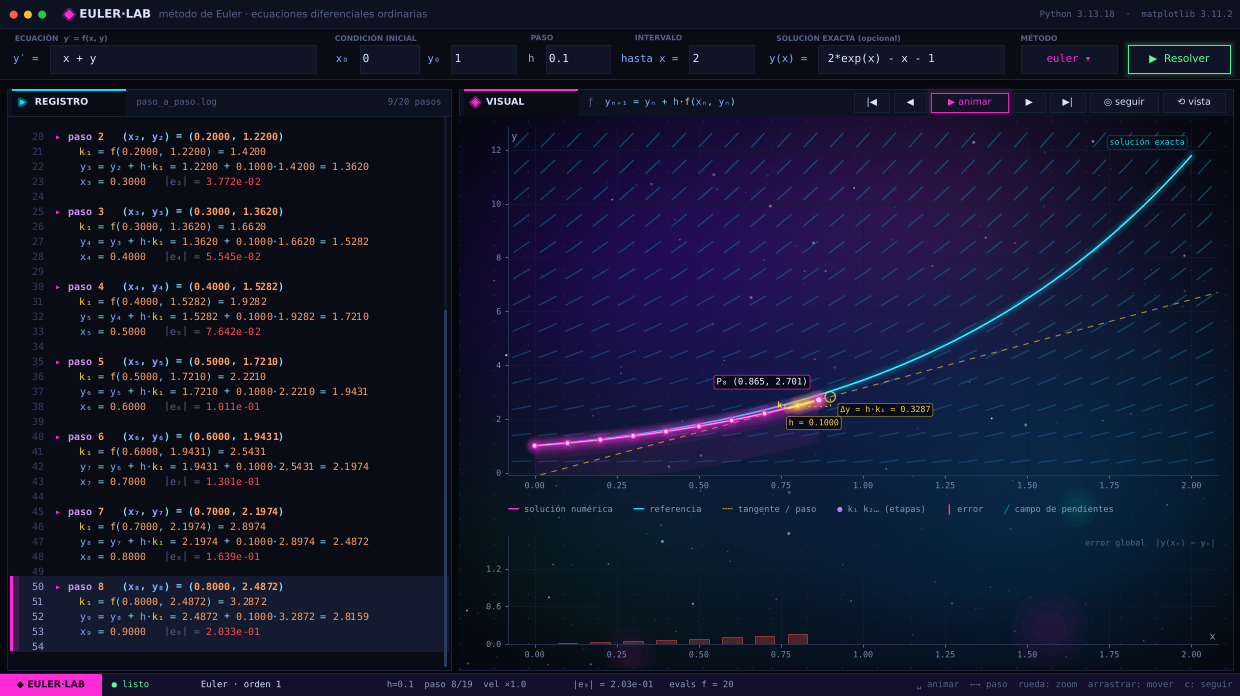

In [20]:
import os
from IPython.display import Image, display
from edo.app import EulerLab

os.makedirs("img", exist_ok=True)

def captura(config, nombre, revelados, seleccion=None, progreso=1.0, seguir=False, calidad="media"):
    app = EulerLab(config, calidad=calidad, animar=False)
    app.ir_a(revelados, seleccion, progreso)
    if seguir:
        app.alternar_seguir()
        for _ in range(80):
            app._mover_camara(0.05)
        app._fijar_vista(app.grafica.ax.get_xlim(), app.grafica.ax.get_ylim())
        app._redibujar()
    ruta = app.guardar(f"img/{nombre}.png", dpi=80)
    plt.close(app.fig)
    display(Image(filename=ruta))

captura(Configuracion("x + y", 0, 1, 0.1, 2, "euler", "2*exp(x) - x - 1"), "app_euler", 9, 8, 0.65)

Con RK4 el registro muestra las cuatro evaluaciones de cada paso y la gráfica marca dónde se hizo cada una (puntos $k_1 \dots k_4$ con su pendiente). Esta captura usa la calidad **alta** con la cámara en modo **seguir** (la vista acompaña al punto que avanza). La franja de error de abajo no sigue el zoom: siempre muestra el intervalo completo.

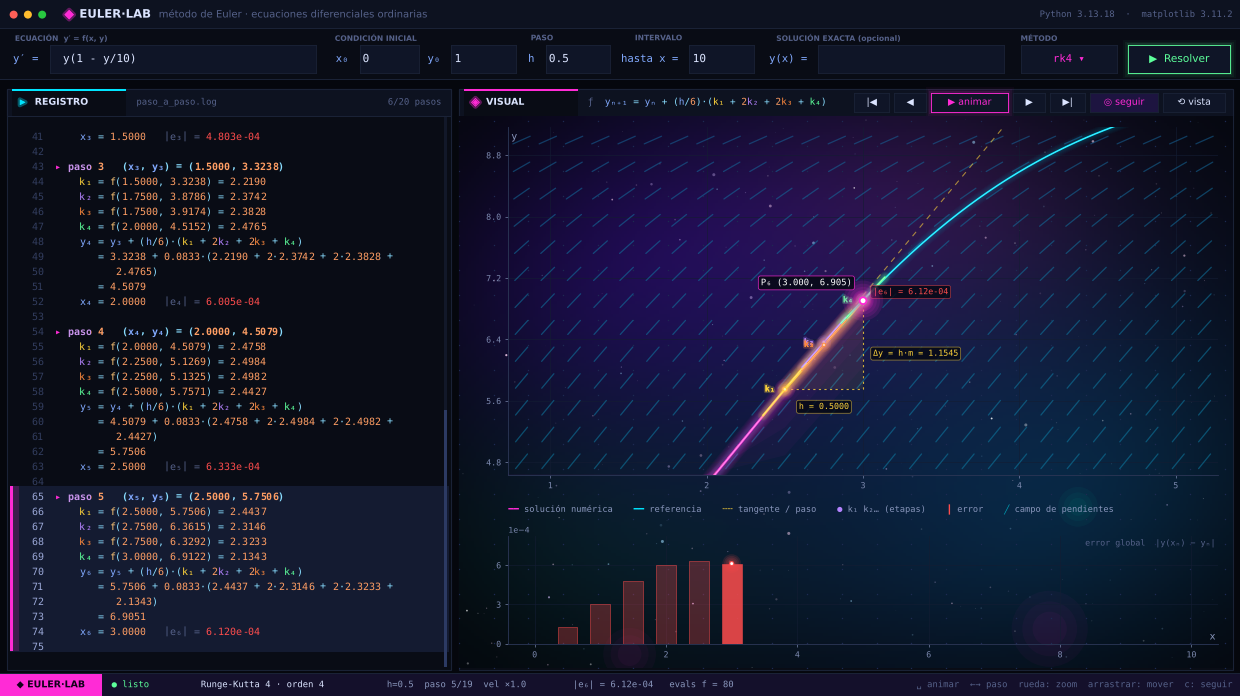

In [21]:
captura(Configuracion("y(1 - y/10)", 0, 1, 0.5, 10, "rk4", ""), "app_rk4", 6, 5, 1.0, seguir=True, calidad="alta")

Y un caso que falla: $y' = -15y$ con $h = 0.25$. El registro marca cada paso inestable y la franja de error crece sin control.

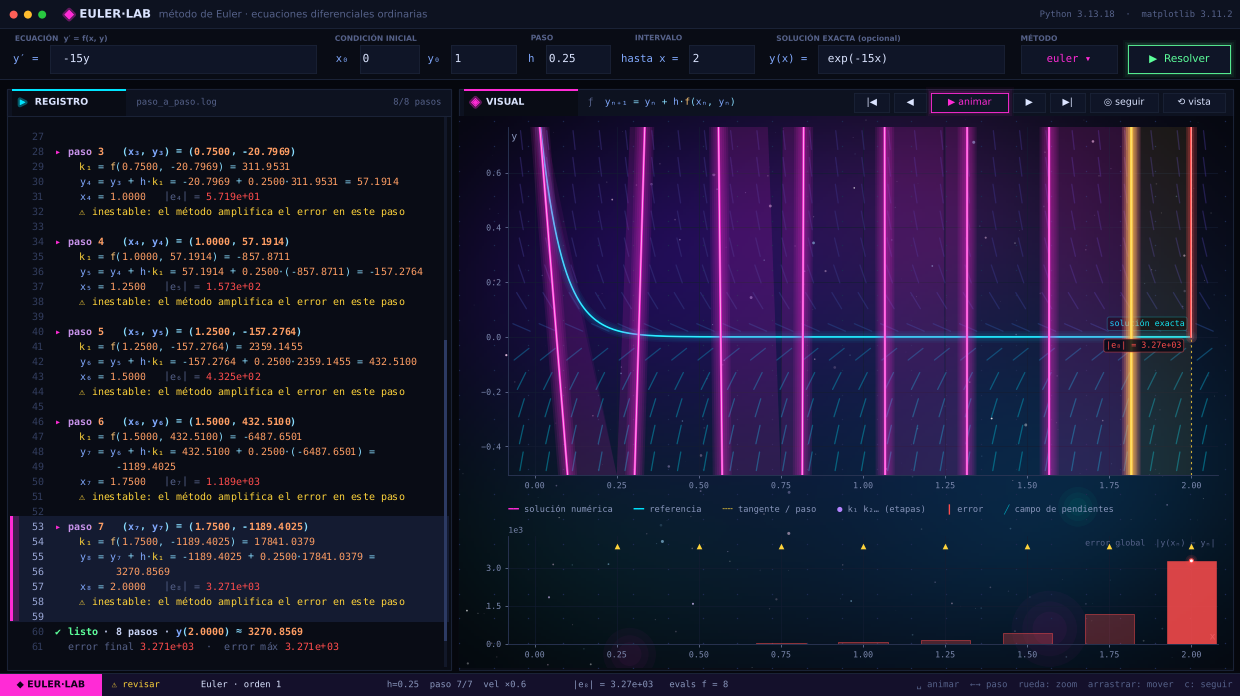

In [22]:
captura(Configuracion("-15y", 0, 1, 0.25, 2, "euler", "exp(-15x)"), "app_inestable", 8, 7, 1.0)

### Cómo está construida

```
edo/
├── expresion.py      texto → función segura (ast + lista blanca)
├── problema.py       ProblemaValorInicial
├── metodos/          un archivo por método + registro por nombre
│   ├── base.py       MetodoNumerico, Paso, Etapa (traza de evaluaciones)
│   ├── euler.py      ← plantilla para métodos nuevos
│   ├── heun.py, rk4.py
├── solucionador.py   resolver(): el ciclo común a todos los métodos
├── simulacion.py     Simulacion: corrida completa paso a paso + referencia + avisos
└── app/              la interfaz (solo dibuja; no sabe nada de Euler)
    ├── tema.py       colores y fuentes
    ├── calidad.py    perfiles alta / media / baja (cuántos efectos dibujar)
    ├── efectos.py    luminiscencia y fondo estelar
    ├── consola.py    registro con resaltado de sintaxis (rasterizado propio)
    ├── grafica.py    campo de pendientes, poligonal, tangente, etapas, error
    └── ventana.py    une todo, eventos y animación
```

La separación importa: **la app no tiene ningún `if metodo == "euler"`**. Toma la lista de métodos del registro, y de cada paso solo usa lo que el método anotó (`Paso.etapas`) y lo que el método sabe decir de sí mismo (`formula`, `formula_numerica`, `funcion_estabilidad`). Por eso un método nuevo aparece en la app sin tocarla.

**Luminiscencia.** Matplotlib no tiene "brillo": cada trazo importante se dibuja varias veces debajo de sí mismo, cada copia más ancha y más transparente, con un núcleo casi blanco encima (como un tubo de neón).

**Fondo.** Detrás de los ejes de datos (transparentes) hay una imagen con degradado, nebulosa y viñeta, más polvo de estrellas, orbes desenfocados y una retícula de puntos. Es fijo: se dibuja una sola vez por tamaño de ventana.

**Rendimiento.** Matplotlib dibuja con el **CPU** (biblioteca Agg), no con la tarjeta de video: lo que decide la fluidez es cuánto se dibuja por cuadro y cuántos píxeles tiene la ventana. Por eso la ventana se compone de capas que se guardan ya dibujadas y solo se repintan cuando cambia lo que muestran:

| Capa | Se repinta cuando... |
|---|---|
| fija (barras, paneles, botones, fondo) | cambia el método, la fórmula o el tamaño de la ventana |
| registro | se revela o selecciona un paso, o se desplaza |
| base (ejes, campo de pendientes, referencia) | se mueve la vista (zoom, arrastrar, cámara "seguir") |
| franja de error | se revela o selecciona un paso |
| dinámica (poligonal, tangente, etapas) | en cada cuadro de la animación |
| estado y cursor | cambia su texto (p. ej. coordenadas del ratón) |

Cada actualización copia a la pantalla (*blit*) solo la zona que cambió. Además, el registro no usa cientos de objetos `Text`: cada carácter se rasteriza **una vez** con FreeType y los renglones se arman con NumPy y se guardan en caché; los campos de texto repintan solo su rectángulo al escribir (el `TextBox` de matplotlib redibuja toda la ventana en cada tecla). Una prueba automática compara la pantalla así compuesta contra un dibujo completo, píxel por píxel, después de cada tipo de interacción.

## 6. Agregar otro método

Un método nuevo es una clase que hereda de `MetodoNumerico` e implementa `paso`. Si evalúa $f$ con `self.evaluar(...)`, cada evaluación queda registrada y la app la dibuja.

### 6.1 Punto medio (orden 2)

$$
k_1 = f(x_n, y_n), \qquad k_2 = f\!\left(x_n + \tfrac{h}{2},\; y_n + \tfrac{h}{2}k_1\right), \qquad y_{n+1} = y_n + h\,k_2 .
$$

In [23]:
from edo.formato import num, nump, sub

@registrar
class PuntoMedio(MetodoNumerico):
    nombre = "punto_medio"
    nombre_completo = "Punto medio"
    orden = 2
    formula = "yₙ₊₁ = yₙ + h·k₂"

    def paso(self, f, t, y, h):
        k1 = self.evaluar(f, t, y, "k1")
        k2 = self.evaluar(f, t + h / 2, y + h / 2 * k1, "k2")
        return y + h * k2

    # Opcionales: estabilidad (para los avisos) y fórmula con números (para el registro)
    def funcion_estabilidad(self, z):
        return 1 + z + z**2 / 2

    def formula_numerica(self, paso):
        n, k2 = paso.indice, paso.etapas[1].pendiente
        return f"y{sub(n+1)} = y{sub(n)} + h·k₂ = {num(paso.y)} + {num(paso.h)}·{nump(k2)} = {num(paso.y_siguiente)}"

print("Registrados:", metodos_disponibles())
sim = Simulacion(Configuracion("x + y", 0, 1, 0.1, 1, "punto_medio", "2exp(x) - x - 1"))
p = sim.pasos[0]
for e in p.etapas:
    print(f"  {e.etiqueta} = f({e.t:.2f}, {float(e.y):.4f}) = {float(e.pendiente):.4f}")
print(" ", sim.metodo.formula_numerica(p))
for h, err, orden in orden_observado(pvi, "punto_medio", [0.1, 0.05, 0.025]):
    print(f"h = {h:<6g} error = {err:.3e}   orden ≈ {'—' if np.isnan(orden) else f'{orden:.3f}'}")

Registrados: ['euler', 'heun', 'punto_medio', 'rk4']
  k1 = f(0.00, 1.0000) = 1.0000
  k2 = f(0.05, 1.0500) = 1.1000
  y₁ = y₀ + h·k₂ = 1.0000 + 0.1000·1.1000 = 1.1100
h = 0.1    error = 3.747e-03   orden ≈ —
h = 0.05   error = 9.277e-04   orden ≈ 2.014
h = 0.025  error = 2.304e-04   orden ≈ 2.010


### 6.2 Euler implícito: la respuesta a la inestabilidad

$$
y_{n+1} = y_n + h\, f(x_{n+1}, y_{n+1}).
$$

La incógnita $y_{n+1}$ aparece en los dos lados: en cada paso hay que **resolver una ecuación** (aquí con el método de Newton). A cambio, para $y' = \lambda y$ da $y_{n+1} = \dfrac{y_n}{1 - h\lambda}$, y $R(z) = 1/(1 - z)$ cumple $|R(z)| < 1$ para **todo** $z$ con parte real negativa: es estable con cualquier $h$. Es el método más simple para ecuaciones rígidas.

Euler            avisos: ['aviso']   y(2) ≈ 3.27e+03
Euler implícito  avisos: ninguno   y(2) ≈ 3.86e-06


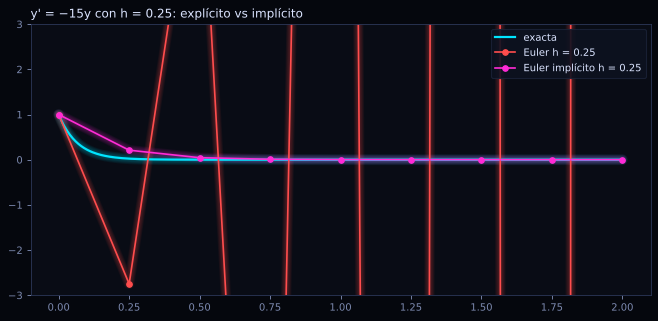

In [24]:
@registrar
class EulerImplicito(MetodoNumerico):
    nombre = "euler_implicito"
    nombre_completo = "Euler implícito"
    orden = 1
    formula = "yₙ₊₁ = yₙ + h·f(xₙ₊₁, yₙ₊₁)"

    def paso(self, f, t, y, h):
        z = y + h * self.evaluar(f, t, y, "k1")              # predicción: un paso de Euler explícito
        for _ in range(30):                                  # Newton para g(z) = z − y − h·f(t+h, z) = 0
            fz = np.asarray(f(t + h, z), dtype=float)
            d = 1e-7 * max(1.0, float(np.max(np.abs(z))))
            dfdz = (np.asarray(f(t + h, z + d), dtype=float) - fz) / d
            dz = (z - y - h * fz) / (1 - h * dfdz)
            z = z - dz
            if np.all(np.abs(dz) <= 1e-12 * (1 + np.abs(z))):
                break
        self.evaluar(f, t + h, z, "k2")                      # la pendiente que realmente se usó
        return z

    def funcion_estabilidad(self, z):
        return 1 / (1 - z)

    def formula_numerica(self, paso):
        n, k = paso.indice, paso.etapas[-1].pendiente
        return (f"y{sub(n+1)} = y{sub(n)} + h·f(x{sub(n+1)}, y{sub(n+1)}) = {num(paso.y)} + {num(paso.h)}·{nump(k)}"
                f" = {num(paso.y_siguiente)}")

fig, ax = plt.subplots(figsize=(10, 4.4))
xe = np.linspace(0, 2, 400)
ax.plot(xe, np.exp(-15 * xe), color=GRAFICA["referencia"], lw=2, label="exacta")
for metodo, c in (("euler", GRAFICA["error"]), ("euler_implicito", GRAFICA["metodo"])):
    s = Simulacion(Configuracion("-15y", 0, 1, 0.25, 2, metodo, "exp(-15x)"))
    ax.plot(s.x_nodos, s.y_nodos, "o-", color=c, ms=5, label=f"{s.metodo} h = 0.25")
    print(f"{str(s.metodo):16} avisos: {[a.nivel for a in s.avisos] or 'ninguno'}   y(2) ≈ {s.y_nodos[-1]:.3g}")
ax.set_ylim(-3, 3); ax.legend(); ax.set_title("y' = −15y con h = 0.25: explícito vs implícito", loc="left")
resplandor(ax)
plt.show()

El método nuevo ya está en el registro, así que la app lo ofrece en el botón de método y dibuja sus dos evaluaciones (la predicción $k_1$ y la pendiente final $k_2$ en $x_{n+1}$):

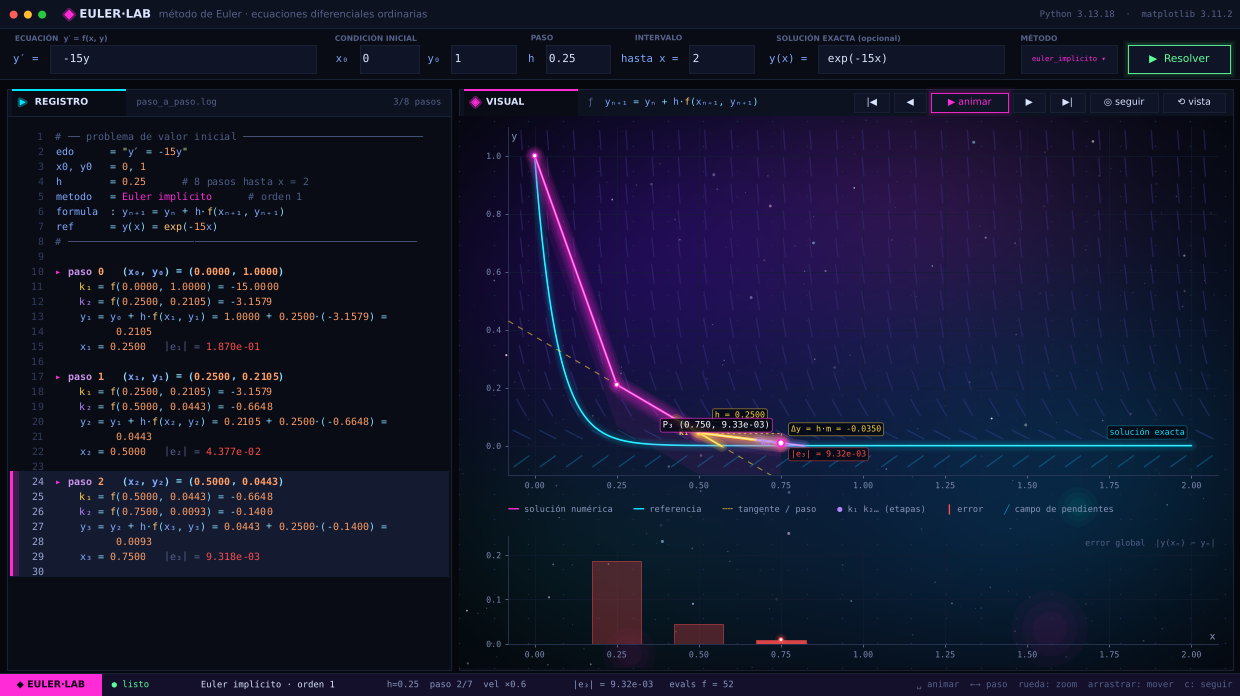

In [25]:
captura(Configuracion("-15y", 0, 1, 0.25, 2, "euler_implicito", "exp(-15x)"), "app_implicito", 3, 2, 1.0)

### 6.3 Para que quede en el proyecto

1. Copia `edo/metodos/euler.py` como `edo/metodos/punto_medio.py` y escribe la clase (con `@registrar`).
2. Agrega `from .punto_medio import PuntoMedio` en `edo/metodos/__init__.py`.
3. Listo: `resolver(pvi, "punto_medio", h=0.1)`, la línea de comandos y la app ya lo conocen.
4. Recomendado: una prueba en `tests/` que verifique su orden con `orden_observado` (como las de Euler, Heun y RK4).

## 7. Conclusiones

- Euler avanza sobre la **recta tangente**: $y_{n+1} = y_n + h\,f(x_n, y_n)$. Se deduce de la definición de derivada, de Taylor o de la regla del rectángulo.
- Error local $O(h^2)$, error global $O(h)$: **orden 1**, comprobado numéricamente.
- Es **condicionalmente estable**: para $y' = \lambda y$ hace falta $h \le 2/|\lambda|$. En problemas rígidos eso obliga a pasos diminutos (o a un método implícito).
- Siempre da números, aunque no tengan sentido: asíntotas, falta de unicidad, $f$ no definida, pérdida de invariantes y redondeo son fallas reales que hay que saber reconocer.
- Python permite escribir el método casi como la fórmula, vectorizarlo con NumPy, visualizarlo con matplotlib y verificarlo contra SciPy y con pruebas automáticas. Su costo (velocidad de los ciclos) no importa para entender el método y se resuelve con las herramientas del ecosistema cuando sí importa.
- La arquitectura (problema / método / ciclo / simulación / interfaz) hace que agregar un método sea escribir una clase pequeña.

### Referencias

- L. Euler, *Institutionum calculi integralis*, vol. 1, San Petersburgo, 1768.
- E. Hairer, S. P. Nørsett, G. Wanner, *Solving Ordinary Differential Equations I*, Springer (secciones I.7 y II.1: historia y convergencia del método de Euler).
- J. C. Butcher, "A history of Runge–Kutta methods", *Applied Numerical Mathematics* 20 (1996) 247–260.
- C. F. Curtiss, J. O. Hirschfelder, "Integration of stiff equations", *PNAS* 38 (1952) 235–243.
- G. Dahlquist, "A special stability problem for linear multistep methods", *BIT* 3 (1963) 27–43.
- R. L. Burden, J. D. Faires, *Análisis Numérico*, cap. 5.
- D. G. Zill, *Ecuaciones Diferenciales con Aplicaciones de Modelado*, sec. 2.6.